# APRENDIZAJE AUTOMÁTICO Y ANÁLISIS VISUAL DE DATOS
Jaime Rodrigo Roldán Corcelles

## Ejercicio práctico: Algoritmos básicos de clasificación

### EJERCICIOS BÁSICOS
1) (0.75 Ptos) Modifique la gráfica que se muestra en el apartado “Base de datos Iris” de la práctica para que:
 * Las muestras de la variedad Setosa se representen mediante triángulos verdes.
 * Las muestras Versicolor se representen mediante cuadrados naranjas.
 * La leyenda se dibuje en la parte inferior derecha de la gráfica (pista: lower right).
 * Muestre la salida obtenida.

In [122]:
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt

In [123]:
df = pd.read_csv('data/iris.csv', header=None)
df.head()

,0,1,2,3,4
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


Para las muestras de Setosa con triangulos verdes se pone la variable color en 'green' y la variable marker en '^'.

Para las muestras de Versicolor con cuadrados naranjas se pone la variable color en 'orange' y la variable marker en 's'.

Para poner la leyenda en la parte inferior derecha ` ` `plt.legend(loc='lower right')` ` `

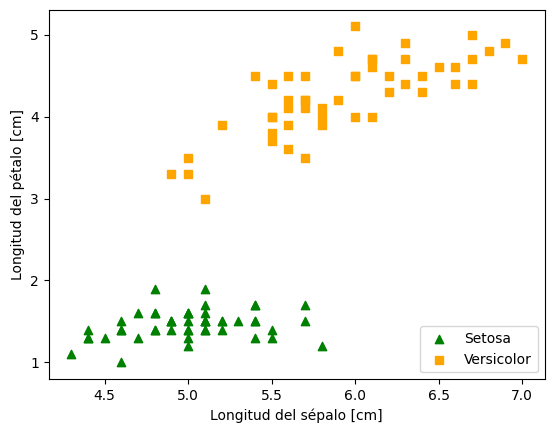

In [124]:
# Elegir setosa y versicolor
y = df.iloc[0:100, 4].values
y = np.where(y == 'Iris-setosa', -1, 1)
# extraer los atributos de la longitud del sépalo y del pétalo
X = df.iloc[0:100, [0, 2]].values
# Dibujar los datos
# Dibujar las muestras tipo Setosa
plt.scatter(X[y[:]==-1,0], X[y[:]==-1,1], color='green', marker='^', label='Setosa')
# Dibujar las muestras tipo Versicolor
plt.scatter(X[y[:]==1,0], X[y[:]==1,1], color='orange', marker='s', label='Versicolor')
# Dibujar leyenda y etiquetar los ejes
plt.xlabel('Longitud del sépalo [cm]')
plt.ylabel('Longitud del pétalo [cm]')
plt.legend(loc='lower right')
plt.show()

2) (0.75 Ptos) Imagine que quiere mostrar el detalle ampliado de las muestras que tienen una longitud del sépalo y una longitud del pétalo concretos, como el siguiente ejemplo: <br>
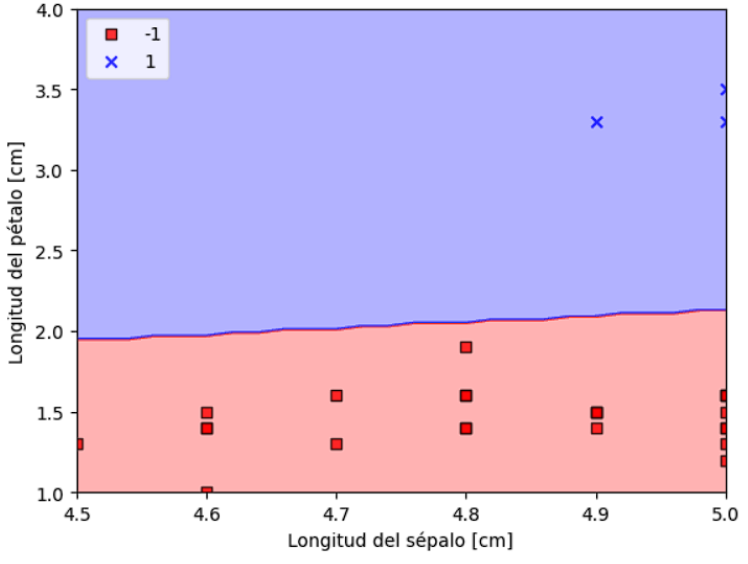 <br>
Cree una nueva función denominada pintar_regiones_decision_zoom basándose en la función pintar_regiones_decision para ampliar las muestras que tienen una longitud del sépalo de entre 5 y 6 centímetros y una longitud del pétalo de entre 1.5 y 4 centímetros.<br>
    a) ¿Cuál sería su código?<br>
    b) Muestre una captura con la salida.

In [125]:
class Perceptron(object):
    """Perceptrón.
    
    Parámetros
    ----------
    eta : float
      Tasa de aprendizaje (entre 0.0 y 1.0)
    n_epoc : int
      Cantidad de épocas de entrenamiento
    estado_aleatorio : int
      Semilla generadora de número aleatorios para la inicialización de pesos
      aleatorios
    
    Atributos
    ---------
    w_ : 1d-array
      Pesos de la red.
    errores_ : list
      Cantidad de clasificaciones erróneas en cada época.
         
    """
    def __init__(self, eta=0.01, n_epoc=50, estado_aleatorio=1):
        self.eta = eta
        self.n_epoc = n_epoc
        self.estado_aleatorio = estado_aleatorio
    
    def entrenar(self, X, y):
        """ Ajustar los datos de entrenamiento
        
        Parámetros
        ----------
        X : {array-like}, shape = [n_muestras, n_features]
          Vectores de entrenamiento, donde n_muestras es la cantidad
          de muestras y n_features es la cantidad de rasgos/atributos.
        y : array-like, shape = [n_examples]
          Valores objetivos/deseados.
        
        Devuelve
        -------
        self : objecto
        
        """
        rgen = np.random.RandomState(self.estado_aleatorio)
        self.w_ = rgen.normal(loc=0.0, scale=0.01,
                              size=1 + X.shape[1])
        self.errores_ = []
        
        for _ in range(self.n_epoc):
            errores = 0
            for xi, objetivo in zip(X, y):
                diferencia = self.eta * (objetivo - self.prediccion(xi))
                self.w_[0] += diferencia
                self.w_[1:] += diferencia * xi                
                errores += int(diferencia != 0.0)
            self.errores_.append(errores)
        return self
    
    def potencial(self, X):
        """Calcular el potencial sináptico"""
        return np.dot(X, self.w_[1:]) + self.w_[0]
    
    def prediccion(self, X):
        """Devuelve la etiqueta de clase para cada muestra"""
        return np.where(self.potencial(X) >= 0.0, 1, -1)
    

# Crear perceptrón con 10 épocas y tasa de 0.1
percep = Perceptron(eta=0.1, n_epoc=10)
# Entrenar perceptrón con las 100 muestras de Iris
percep.entrenar(X, y)

In [126]:
from matplotlib.colors import ListedColormap
def pintar_regiones_decision_zoom(X, y, clasificador, resolucion=0.02):
    # Configurar los marcadores y el mapa de color
    marcadores = ('s', 'x', 'o', '^', 'v')
    colores = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    # Asignación de colores a las clases
    cmap = ListedColormap(colores[:len(np.unique(y))])
    
    # Preparar los márgenes de la superficie de decisión
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    # Preparar los valores puntuales de la superficie de decisión y el valor del
    # clasifidor para dichos puntos
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolucion),
                           np.arange(x2_min, x2_max, resolucion))
    
    # Pasamos la entrada a matriz con dos columnas para calcular la salida del
    # clasificador
    Z = clasificador.prediccion(np.array([xx1.reshape(-1), xx2.reshape(-1)]).T)
    # Convertimos la salida predicha al formato adecuado para pintar la 
    # superficie
    Z = Z.reshape(xx1.shape)

    # Pintar el contorno de la superficie de decisión y se rellena también
    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)

    #Aquí se marcarían los márgenes
    plt.xlim(5, 6)
    plt.ylim(1.5, 4.0)
    
    # Pintar las muestras en la superficie de decisión
    for idx, cl in enumerate(np.unique(y)):
         plt.scatter(x=X[y == cl, 0],
                     y=X[y == cl, 1],
                     alpha=0.8,
                     c=colores[idx],
                     marker=marcadores[idx],
                     label=cl,
                     edgecolor='black')

C:\Users\rodri\AppData\Local\Temp\ipykernel_10996\3872733191.py:34: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(x=X[y == cl, 0],


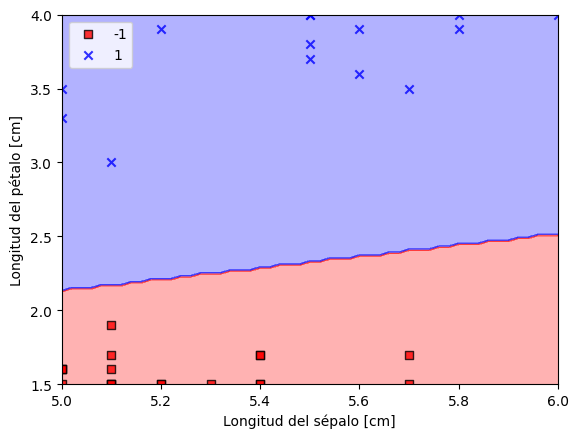

In [127]:
pintar_regiones_decision_zoom(X, y, clasificador=percep)
plt.xlabel('Longitud del sépalo [cm]')
plt.ylabel('Longitud del pétalo [cm]')
plt.legend(loc='upper left')
plt.show()

3) (1.5 Ptos) Modifique el apartado “Adaline estocástica aplicada a Iris estandarizada” para entrenar una adaline estocástica con los siguientes parámetros: <br>
i) Tasa de aprendizaje: 0.0005<br>
ii) Épocas de entrenamiento: 5<br>
Use el mismo conjunto de entrenamiento, es decir, rasgos 0 y 2 estandarizados.

In [128]:
class AdalineDGS(object):
    """ADAptive LInear NEuron con Descenso por el Gradiente eStocástico.
    
    Parámetros
    ------------
    eta : float
        Tasa de aprendizaje (entre 0.0 y 1.0)
    n_epoc : int
        Cantidad de épocas de entrenamiento
    barajar : bool (por defecto: True)
        Si True, baraja las muestras de entrenamiento en cada época para
        evitar ciclos.
    random_state : int
        Semilla generadora de número aleatorios para la inicialización de los
        pesos aleatorios.
    
    
    Atributos
    -----------
    w_ : 1d-array
        Pesos sinápticos de la neurona.
    coste_ : list
        Error cuadrático medio en las muestras de entrenamiento
        en cada época.
    
    
    """
    def __init__(self, eta=0.01, n_epoc=10,
              barajar=True, estado_aleatorio=None):
        self.eta = eta
        self.n_epoc = n_epoc
        self.w_inicializados = False
        self.barajar = barajar
        self.estado_aleatorio = estado_aleatorio
    
    def entrenar(self, X, y):
        """ Entrena la neurona con las muestras de entrenamiento
        
        Parámetros
        ----------
        X : {array-like}, shape = [n_examples, n_features]
            Vectores de entrenamiento, donde n_examples
            es el número de muestras y n_features es el número de 
            rasgos/atributos.
        y : array-like, shape = [n_examples]
            Valores objetivos/deseados.
        
        Devuelve
        -------
        self : objecto
        
        """
        self._inicializar_pesos(X.shape[1])
        self.coste_ = []
        for i in range(self.n_epoc):
            if self.barajar:
                X, y = self._barajar(X, y)
            coste_epoca = []
            for xi, objetivo in zip(X, y):
                coste_epoca.append(self._actualizar_pesos(xi, objetivo))
            coste_medio = sum(coste_epoca) / len(y)
            self.coste_.append(coste_medio)
        return self
    
    def entrenar_parcial(self, X, y):
        """Entrena con la muestras sin reiniciar los pesos cada vez"""
        if not self.w_inicializados:
            self._inicializar_pesos(X.shape[1])
        if y.ravel().shape[0] > 1:
            for xi, objetivo in zip(X, y):
                self._actualizar_pesos(xi, objetivo)
        else:
            self._actualizar_pesos(X, y)
        return self
    
    def _barajar(self, X, y):
        """Baraja los datos de entrenamiento"""
        r = self.rgen.permutation(len(y))
        return X[r], y[r]
    
    def _inicializar_pesos(self, n_rasgos):
        """Inicializa los pesos con números aleatorios pequeños"""
        self.rgen = np.random.RandomState(self.estado_aleatorio)
        self.w_ = self.rgen.normal(loc=0.0, scale=0.01,
                                   size=1 + n_rasgos)
        self.w_inicializados = True
    
    def _actualizar_pesos(self, xi, objetivo):
        """Aplica la regla de aprendizaje de la Adaline para actualizar 
        los pesos"""
        salida = self.activacion(self.potencial(xi))
        error = (objetivo - salida)
        self.w_[0] += self.eta * error
        self.w_[1:] += self.eta * xi.dot(error)        
        coste = 0.5 * error**2
        return coste
    
    def potencial(self, X):
        """Calcula el potencial sináptico"""
        return np.dot(X, self.w_[1:]) + self.w_[0]
    
    def activacion(self, Pot):
        """Calcula la función de activación/transferencia 
        (lineal en este caso)"""
        return Pot
    
    def prediccion(self, X):
        """Devuelve la etiqueta de clase para cada muestra"""
        return np.where(self.activacion(self.potencial(X))
                        >= 0.0, 1, -1)

In [129]:
def pintar_regiones_decision(X, y, clasificador, resolucion=0.02):
    # Configurar los marcadores y el mapa de color
    marcadores = ('s', 'x', 'o', '^', 'v')
    colores = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    # Asignación de colores a las clases
    cmap = ListedColormap(colores[:len(np.unique(y))])
    
    # Preparar los márgenes de la superficie de decisión
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    # Preparar los valores puntuales de la superficie de decisión y el valor del
    # clasifidor para dichos puntos
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolucion),
                           np.arange(x2_min, x2_max, resolucion))
    
    # Pasamos la entrada a matriz con dos columnas para calcular la salida del
    # clasificador
    Z = clasificador.prediccion(np.array([xx1.reshape(-1), xx2.reshape(-1)]).T)
    # Convertimos la salida predicha al formato adecuado para pintar la 
    # superficie
    Z = Z.reshape(xx1.shape)

    # Pintar el contorno de la superficie de decisión y se rellena también
    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())
    
    # Pintar las muestras en la superficie de decisión
    for idx, cl in enumerate(np.unique(y)):
         plt.scatter(x=X[y == cl, 0],
                     y=X[y == cl, 1],
                     alpha=0.8,
                     c=colores[idx],
                     marker=marcadores[idx],
                     label=cl,
                     edgecolor='black')

a) Muestre las dos gráficas resultantes: evolución del error cuadrático medio en función de la época y gráfica con superficie de decisión.<br>

C:\Users\rodri\AppData\Local\Temp\ipykernel_10996\112310722.py:31: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(x=X[y == cl, 0],


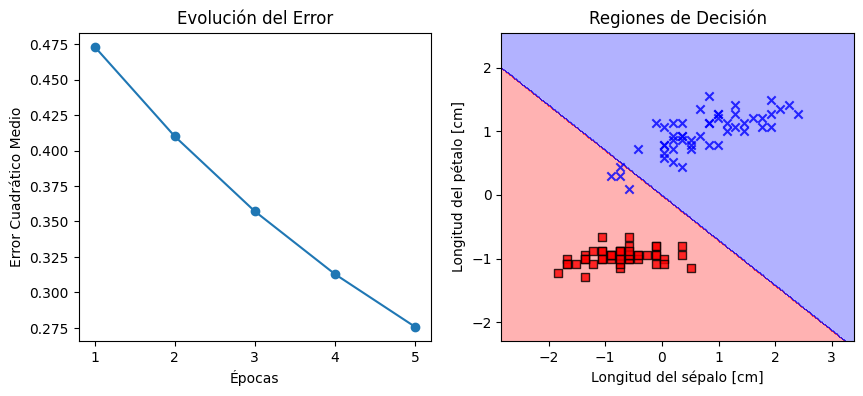

In [130]:
# Preparación de datos 
X_3 = df.iloc[0:100, [0, 2]].values
y_3 = np.where(df.iloc[0:100, 4].values == 'Iris-setosa', -1, 1)

# Estandarización (Basado en la fórmula de la página 70 de los apuntes)
X_3_std = np.copy(X_3)
X_3_std[:,0] = (X_3[:,0] - X_3[:,0].mean()) / X_3[:,0].std()
X_3_std[:,1] = (X_3[:,1] - X_3[:,1].mean()) / X_3[:,1].std()

# Entrenamos con los parámetros solicitados (eta: 0.0005, épocas: 5)
ada_3 = AdalineDGS(n_epoc=5, eta=0.0005)
ada_3.entrenar(X_3_std, y_3)

# Dibujamos la evolución del ECM 
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, len(ada_3.coste_) + 1), ada_3.coste_, marker='o')
plt.xlabel('Épocas')
plt.ylabel('Error Cuadrático Medio')
plt.title('Evolución del Error')

# Dibujamos la superficie de decisión 
plt.subplot(1, 2, 2)
pintar_regiones_decision(X_3_std, y_3, clasificador=ada_3)
plt.xlabel('Longitud del sépalo [cm]')
plt.ylabel('Longitud del pétalo [cm]')
plt.title('Regiones de Decisión')
plt.show()

b) ¿Ha resuelto el problema de clasificación correctamente considerando el signo de la salida? Razone su respuesta apoyándose en alguna de las gráficas del apartado anterior.<br>


No. Al observar la gráfica de regiones de decisión, se puede apreciar que la línea divisoria no separa correctamente las muestras de la clase 1 de las de la clase -1. Hay 4 cruces en la zona roja que no corresponden

c) En este problema de clasificación y considerando directamente la salida de una Adaline (NO su signo), ¿cree que es posible lograr un error cuadrático medio de cero? Razone su respuesta.<br>

No. En este tipo de neuronas artificiales no es habitual llegar al error nulo. Esto se debe a que Adaline intenta minimizar una función de coste continua basada en la distancia de los puntos al hiperplano; dado que los datos reales presentan dispersión, es imposible que todos los puntos coincidan exactamente con los valores deseados (1 o -1), por lo que siempre habrá un residuo cuadrático.

4) (1.5 Ptos) Dibuje en una gráfica todas las muestras que hay en la base de datos Iris atendiendo al rasgo 0 y 2. Dibuje cada una de las tres clases con un marcador diferente. <br>
a) Muestre el código que ha usado y explique la modificación que ha realizado.<br>
b) Muestre la gráfica.<br>

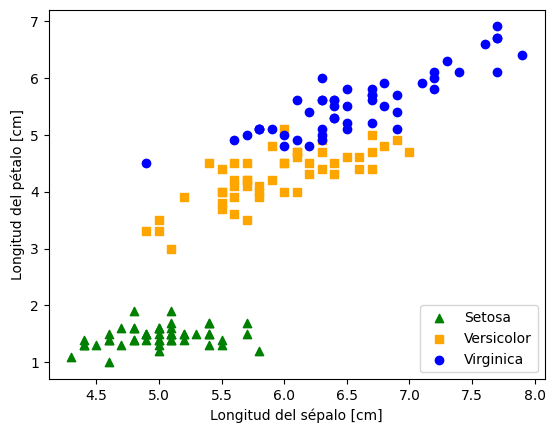

In [131]:
y_4 = df.iloc[0:150, 4].values
# extraer los atributos de la longitud del sépalo y del pétalo
X_4 = df.iloc[0:150, [0, 2]].values
# Dibujar los datos
# Dibujar las muestras tipo Setosa
plt.scatter(X_4[:50, 0], X_4[:50, 1], color='green', marker='^', label='Setosa')
# Dibujar las muestras tipo Versicolor
plt.scatter(X_4[50:100, 0], X_4[50:100, 1], color='orange', marker='s', label='Versicolor')
# Dibujar las muestras tipo Virginica
plt.scatter(X_4[100:150, 0], X_4[100:150, 1], color='blue', marker='o', label='Virginica')
# Dibujar leyenda y etiquetar los ejes
plt.xlabel('Longitud del sépalo [cm]')
plt.ylabel('Longitud del pétalo [cm]')
plt.legend(loc='lower right')
plt.show()

c) ¿Qué modelo o técnica utilizaría para clasificar estas muestras? Razone su respuesta.

Utilizaría la Técnica de uno contra todos. Como se detalla en los apuntes, un perceptrón o Adaline solo puede realizar clasificaciones binarias. Para tres clases, se deben entrenar tres clasificadores distintos, donde cada uno se especializa en detectar una clase en particular frente a las demás.

5) (1.5 Ptos) Cargue el fichero glass.csv en su Google Colab. A continuación lea el fichero y guarde su contenido en una variable. Si quiere, puede usar el siguiente código: df5 = pd.read_csv('glass.csv', names=['ID','RI','Na','Mg','Al','Si','K','Ca', 'Ba','Fe','ClaseCristal'])
* La clase deseada es ClaseCristal y hay siete clases de cristales, realiza la siguiente transformación:
    - Los valores 1, 2, 3 y 4 (cristales de ventana) serán la clase negativa.
    - Los valores 5, 6 y 7 (cristales no de ventana) serán la clase positiva.
* Seleccione y estandarice los siguientes rasgos:
    - Sodio (Na)
    - Aluminio (Al)
* Clasifique estos datos mediante una Adaline estocástica con 20 épocas de entrenamiento, una tasa de aprendizaje constante de 0.005 y un estado aleatorio inicial de 1. <br>

a) Dibuje el estado final de las regiones de decisión y la evolución del error cuadrático medio a lo largo de las épocas.

C:\Users\rodri\AppData\Local\Temp\ipykernel_10996\112310722.py:31: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(x=X[y == cl, 0],


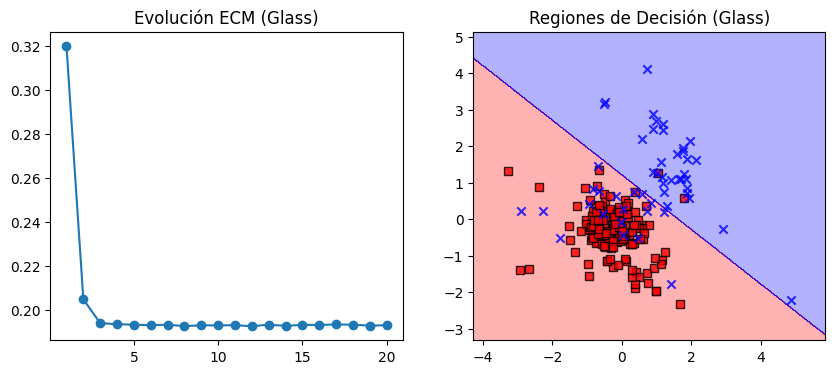

In [132]:
# Cargamos los datos
df5 = pd.read_csv('data/glass.csv', names=['ID','RI', 'Na', 'Mg', 'Al','Si', 'K', 'Ca', 'Ba', 'Fe', 'ClaseCristal'])
y_glass = np.where(df5['ClaseCristal'] <= 4, -1, 1)

# Seleccionamos (Sodio Na y Aluminio Al) y estandarización
X_glass = df5[['Na', 'Al']].values
X_glass_std = (X_glass - X_glass.mean(axis=0)) / X_glass.std(axis=0)

ada_glass = AdalineDGS(eta=0.005, n_epoc=20, estado_aleatorio=1)
ada_glass.entrenar(X_glass_std, y_glass)

# Dubujamos las gráficas
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, len(ada_glass.coste_) + 1), ada_glass.coste_, marker='o')
plt.title('Evolución ECM (Glass)')

plt.subplot(1, 2, 2)
pintar_regiones_decision(X_glass_std, y_glass, clasificador=ada_glass)
plt.title('Regiones de Decisión (Glass)')
plt.show()

b) ¿Clasifica bien todas las muestras? ¿en qué clase comete más fallos? Razone sus respuestas haciendo referencia a alguna gráfica del apartado anterior.

No clasifica bien todas las muestras. En la gráfica de regiones de decisión se observará que hay puntos de una clase que caen en el área de color asignada a la otra. Esto ocurre cuando las componentes del vector de pesos no pueden ajustarse perfectamente debido a que los datos no son linealmente separables o presentan una dispersión que provoca "saltos" en la solución. Cometerá más fallos en aquella clase cuyos rasgos (Na y Al) estén más solapados con los de la clase contraria.

### EJERCICIO AVANZADO
6) (2 Ptos) Comparar el error cuadrático medio del Adaline frente al Adaline estocástico en la base de datos Iris, para valores de la tasa de aprendizaje comprendidos entre 0.001 y 0.01, en incrementos de 0.001. Sea $p$ la cantidad de patrones, el Error Cuadrático Medio se define como:

$$ECM = \frac{1}{p} \sum_{i=1}^{p} (\hat{y}^{(i)} - h^{(i)})^2$$

* Los rasgos serán la longitud del sépalo y la del pétalo estandarizados.
* Las clases deseadas serán Setosa y Versicolor.
* El número de épocas será 20 en todos los casos.
* El error mostrado será el obtenido después de las 20 épocas de entrenamiento.
* Muestre los resultados en una sola gráfica con dos curvas, los resultados del Adaline se verán en verde, y los del Adaline estocástico en azul.
* El eje horizontal representará los diferentes valores de la tasa de aprendizaje.
* El eje vertical (el de los errores) debe tener escala logarítmica para apreciar mejor las diferencias.

In [133]:
class AdalineDG(object):
    """ADAptive LInear NEuron con Descenso por el Gradiente por lotes.
    
    Parámetros
    ----------
    eta : float
        Tasa de aprendizaje (entre 0.0 y 1.0)
    n_epoc : int
        Cantidad de épocas de entrenamiento
    estado_aleatorio : int
      Semilla generadora de número aleatorios para la inicialización de pesos
      aleatorios
    
    Atributos
    ---------
    w_ : 1d-array
        Pesos sinápticos de la red.
    coste_ : list
        Suma de errores cuadráticos en cada época calculados con la función 
        de coste.        
    
    """
    def __init__(self, eta=0.01, n_epoc=50, estado_aleatorio=1):
        self.eta = eta
        self.n_epoc = n_epoc
        self.estado_aleatorio = estado_aleatorio
    
    def entrenar(self, X, y):
        """ Entrenar con muestras de entrenamiento.
        
        Parámetros
        ----------
        X : {array-like}, shape = [n_ejemplos, n_rasgos]
            Vectores de entrenamiento, donde n_ejemplos
            es el número de muestras y 
            n_rasgos es el número de rasgos/atributos.
        y : array-like, shape = [n_ejemplos]
            Valores objetivos/deseados.
        
        Devuelve
        --------
        self : objecto
        
        """
        rgen = np.random.RandomState(self.estado_aleatorio)
        self.w_ = rgen.normal(loc=0.0, scale=0.01,
                              size=1 + X.shape[1])
        self.coste_ = []
        
        for i in range(self.n_epoc):
            # Cálculo de potenciales para las muestras del lote
            pot= self.potencial(X)
            # Cálculo de las salidas para el lote
            salidas = self.activacion(pot)
            # Cálculo de errores
            errores = (y - salidas)
            # Ajuste de cada peso
            self.w_[0] += self.eta * errores.sum()
            self.w_[1:] += self.eta * X.T.dot(errores)            
            # Anotación del coste o error en esta i-ésima época
            coste_epoca = (errores**2).sum() / 2.0
            self.coste_.append(coste_epoca)
        return self
    
    def potencial(self, X):
        """Calcular el potencial sináptico para las muestras de un lote"""
        return np.dot(X, self.w_[1:]) + self.w_[0]
    
    def activacion(self, Pot):
        """Calcula la función de activación/transferencia"""
        return Pot
    
    def prediccion(self, X):
        """Devuelve la etiqueta de clase para cada muestra"""
        return np.where(self.activacion(self.potencial(X))
                        >= 0.0, 1, -1)

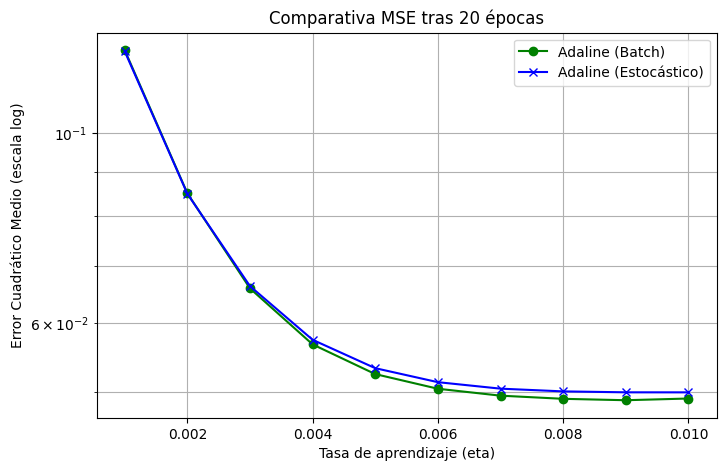

In [134]:
# Rango de tasas de aprendizaje
etas = np.arange(0.001, 0.011, 0.001)
ecm_dg = []
ecm_dgs = []
X_std = np.copy(X_3_std) # o vuelve a estandarizar X aquí
p = len(y_3)

for eta in etas:
    # Adaline
    ada_dg = AdalineDG(eta=eta, n_epoc=20, estado_aleatorio=1)
    ada_dg.entrenar(X_std, y)
    # ECM = (1/p) * sum(error^2)
    ecm_dg.append(2 * ada_dg.coste_[-1] / p)

    # Adaline Estocástico
    ada_dgs = AdalineDGS(eta=eta, n_epoc=20, barajar=True, estado_aleatorio=1)
    ada_dgs.entrenar(X_std, y)
    ecm_dgs.append(2 * ada_dgs.coste_[-1])

# Gráfica comparativa
plt.figure(figsize=(8, 5))
plt.plot(etas, ecm_dg, color='green', marker='o', label='Adaline (Batch)')
plt.plot(etas, ecm_dgs, color='blue', marker='x', label='Adaline (Estocástico)')
plt.yscale('log')
plt.xlabel('Tasa de aprendizaje (eta)')
plt.ylabel('Error Cuadrático Medio (escala log)')
plt.title('Comparativa MSE tras 20 épocas')
plt.legend()
plt.grid(True, which="both", ls="-")
plt.show()

### EJERCICIO EXPERTO
7) (2 Ptos) Implementar el Adaline y el Adaline estocástico con tasas de aprendizaje decrecientes. La tasa de aprendizaje en cada época $i$ vendrá dada por:

$$tasa(i) = \eta \cdot \exp(-i/n\_epoc)$$

* Comparar con las versiones estándar de ambos modelos, repitiendo los experimentos del ejercicio de nivel avanzado. Pruebe valores de la tasa de aprendizaje comprendidos entre 0.001 y 0.02, en incrementos de 0.001.
* Use los mismos rasgos y clases que en el ejercicio avanzado. Dibuje una gráfica con dos curvas.
* Explique los resultados obtenidos.

\* *Pista: podría crear dos nuevas subclases redefiniendo únicamente aquellos métodos que crea necesarios.*

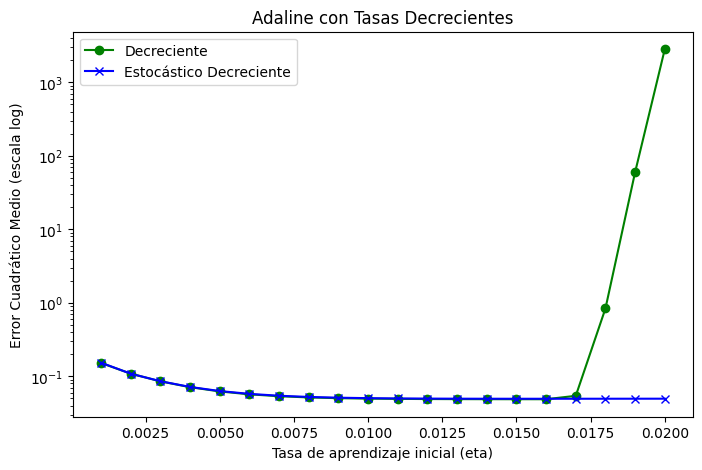

In [135]:
# Subclases con tasa decreciente
class AdalineDG_Decr(AdalineDG):
    def entrenar(self, X, y):
        rgen = np.random.RandomState(self.estado_aleatorio)
        self.w_ = rgen.normal(loc=0.0, scale=0.01, size=1 + X.shape[1])
        self.coste_ = []
        eta_inicial = self.eta
        for i in range(self.n_epoc):
            # Actualización de la tasa en cada época i
            self.eta = eta_inicial * np.exp(-i / self.n_epoc)
            pot = self.potencial(X)
            errores = (y - self.activacion(pot))
            self.w_[0] += self.eta * errores.sum()
            self.w_[1:] += self.eta * X.T.dot(errores)
            self.coste_.append((errores**2).sum() / 2.0)
        return self

class AdalineDGS_Decr(AdalineDGS):
    def entrenar(self, X, y):
        self._inicializar_pesos(X.shape[1])
        self.coste_ = []
        eta_inicial = self.eta
        for i in range(self.n_epoc):
            current_eta = eta_inicial * np.exp(-i / self.n_epoc)
            if self.barajar: X, y = self._barajar(X, y)
            coste_epoca = []
            for xi, objetivo in zip(X, y):
                error = (objetivo - self.activacion(self.potencial(xi)))
                self.w_[0] += current_eta * error
                self.w_[1:] += current_eta * xi.dot(error)
                coste_epoca.append(0.5 * error**2)
            self.coste_.append(sum(coste_epoca) / len(y))
        return self

etas_exp = np.arange(0.001, 0.021, 0.001)
ecm_dg_decr, ecm_dgs_decr = [], []

for eta in etas_exp:
    ada_dg_7 = AdalineDG_Decr(eta=eta, n_epoc=20, estado_aleatorio=1).entrenar(X_std, y)
    ecm_dg_decr.append(2 * ada_dg_7.coste_[-1] / len(y))
    ada_dgs_7 = AdalineDGS_Decr(eta=eta, n_epoc=20, estado_aleatorio=1).entrenar(X_std, y)
    ecm_dgs_decr.append(2 * ada_dgs_7.coste_[-1])

# Gráfica comparativa
plt.figure(figsize=(8, 5))
plt.plot(etas_exp, ecm_dg_decr, color='green', marker='o', label='Decreciente')
plt.plot(etas_exp, ecm_dgs_decr, color='blue', marker='x', label='Estocástico Decreciente')
plt.yscale('log')
plt.xlabel('Tasa de aprendizaje inicial (eta)')
plt.ylabel('Error Cuadrático Medio (escala log)')
plt.title('Adaline con Tasas Decrecientes')
plt.legend()
plt.show()

La conclusión que sacamos del ejercicio es la siguiente:<br>
* Con tasas bajas (mitad izquierda): Ambos modelos aprenden bien y su error es casi cero.
* Con tasas altas (mitad derecha): El método Batch pierde el control y sus errores se disparan brutalmente. En cambio, el Estocástico logra adaptarse y mantiene el error al mínimo.